# Gradient compression on CIFAR-10 (ResNet-50)

Data-parallel training with 4 simulated workers. Each worker takes a quarter of every mini-batch, computes its own gradient and sends a compressed message to the server. Communication is counted as uplink bits per worker (1 MB = 10^6 bytes), summed over every tensor and every step.

In [1]:
import os
import re
import glob
import math
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset

In [2]:
N_WORKERS = 4
EPOCHS = 50
BATCH_SIZE = 128
BASE_LR = 0.01
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4
K_RATIO = 0.1
DIANA_BLOCK = 256
SEED = 42

TRAIN_DIR = "/kaggle/input/datasets/ayush1220/cifar10/cifar10/train/"
RESULTS_DIR = "/kaggle/working/benchmark"
os.makedirs(RESULTS_DIR, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

for found in glob.glob(f"/kaggle/input/**/*_w{N_WORKERS}_e{EPOCHS}_s{SEED}.csv", recursive=True):
    target = os.path.join(RESULTS_DIR, os.path.basename(found))
    if not os.path.exists(target):
        shutil.copy(found, target)
print(sorted(os.listdir(RESULTS_DIR)))

Using device: cuda
['1_bit_sgd_w4_e50_s42.csv', 'diana_ternary_w4_e50_s42.csv', 'ef21_top_10_w4_e50_s42.csv', 'efsgd_top_10_w4_e50_s42.csv', 'uncompressed_sgd_w4_e50_s42.csv']


In [3]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])
val_transform = transforms.ToTensor()

full_train = datasets.ImageFolder(root=TRAIN_DIR, transform=train_transform)
full_val = datasets.ImageFolder(root=TRAIN_DIR, transform=val_transform)

train_size = int(0.9 * len(full_train))
perm = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(SEED)).tolist()
train_dataset = Subset(full_train, perm[:train_size])
val_dataset = Subset(full_val, perm[train_size:])

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                          num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=2, pin_memory=True)

print(f"Classes found: {full_train.classes}")
print(f"Train samples: {len(train_dataset)} | Val samples: {len(val_dataset)}")

Classes found: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train samples: 45000 | Val samples: 5000


In [4]:
def build_model():
    net = models.resnet50(weights=None)
    net.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1)
    net.maxpool = nn.Identity()
    net.fc = nn.Linear(net.fc.in_features, 10)
    return net.to(device)


def layer_slices(net):
    edges = np.cumsum([0] + [p.numel() for p in net.parameters()])
    return [(int(a), int(b)) for a, b in zip(edges[:-1], edges[1:])]


PARAM_COUNT = layer_slices(build_model())[-1][1]
print(f"Trainable parameters: {PARAM_COUNT:,}")

Trainable parameters: 23,520,906


## Compressors

Every compressor works on one layer at a time and takes a `(workers, d)` tensor. It returns the decoded message together with the number of bits each worker needed to encode it.

- Dense: 32 bits per entry.
- Top-K: K values in fp32 plus a ceil(log2 d)-bit index for each.
- 1-bit: one sign bit per entry plus two fp32 reconstruction levels (mean of the positive and of the negative entries).
- Block ternary (DIANA): l2-normalised stochastic ternary quantisation in blocks. Only non-zero entries are sent (in-block index and sign), plus an fp32 norm and an entry count per block. The bit count uses the realised number of non-zeros at every step.

In [5]:
def idx_bits(n):
    return max(1, math.ceil(math.log2(n)))


def worker_bits(n_workers, value, dev):
    return torch.full((n_workers,), float(value), dtype=torch.float64, device=dev)


class Dense:
    def __call__(self, x):
        n, d = x.shape
        return x, worker_bits(n, 32 * d, x.device)


class TopK:
    def __init__(self, ratio):
        self.ratio = ratio

    def __call__(self, x):
        n, d = x.shape
        k = max(1, int(d * self.ratio))
        idx = x.abs().topk(k, dim=1, sorted=False).indices
        out = torch.zeros(n, d, device=x.device, dtype=x.dtype)
        out.scatter_(1, idx, x.gather(1, idx))
        return out, worker_bits(n, k * (32 + idx_bits(d)), x.device)


class OneBit:
    def __call__(self, x):
        n, d = x.shape
        pos = x >= 0
        n_pos = pos.sum(1, keepdim=True).clamp(min=1)
        n_neg = (~pos).sum(1, keepdim=True).clamp(min=1)
        pos_level = (x * pos).sum(1, keepdim=True) / n_pos
        neg_level = (x * ~pos).sum(1, keepdim=True) / n_neg
        out = torch.where(pos, pos_level, neg_level)
        return out, worker_bits(n, d + 64, x.device)


class BlockTernary:
    def __init__(self, block):
        self.block = block

    def __call__(self, x):
        n, d = x.shape
        b = min(self.block, d)
        nb = math.ceil(d / b)
        padded = F.pad(x, (0, nb * b - d)).view(n, nb, b)
        norm = padded.norm(dim=2, keepdim=True)
        keep = torch.rand_like(padded) * norm < padded.abs()
        out = (norm * padded.sign() * keep).view(n, nb * b)[:, :d]
        nnz = keep.sum(dim=(1, 2)).to(torch.float64)
        bits = nnz * (idx_bits(b) + 1) + nb * (32 + idx_bits(b + 1))
        return out, bits


def compress_layers(compressor, x, slices):
    out = torch.empty_like(x)
    bits = torch.zeros(x.shape[0], dtype=torch.float64, device=x.device)
    for a, b in slices:
        c, nb = compressor(x[:, a:b])
        out[:, a:b] = c
        bits += nb
    return out, bits

## Algorithms

All methods use heavy-ball momentum 0.9 and weight decay 5e-4 with the same cosine schedule. EFSGD and 1-bit SGD keep a local momentum buffer and an error memory on each worker and compress `lr * momentum + error`. EF21 and DIANA compress gradient differences and apply momentum on the server to the aggregated estimate. For plain SGD the two placements are equivalent.

In [6]:
class PlainSGD:
    def __init__(self, n_workers, slices, dev):
        self.n = n_workers
        self.dim = slices[-1][1]
        self.dev = dev
        self.buf = torch.zeros(self.dim, device=dev)

    def step(self, grads, lr):
        self.buf.mul_(MOMENTUM).add_(grads.mean(0))
        return lr * self.buf, worker_bits(self.n, 32 * self.dim, self.dev)


class ErrorFeedbackSGD:
    def __init__(self, n_workers, slices, dev, compressor):
        self.slices = slices
        self.compressor = compressor
        dim = slices[-1][1]
        self.mom = torch.zeros(n_workers, dim, device=dev)
        self.err = torch.zeros(n_workers, dim, device=dev)

    def step(self, grads, lr):
        self.mom.mul_(MOMENTUM).add_(grads)
        target = self.mom.mul(lr).add_(self.err)
        sent, bits = compress_layers(self.compressor, target, self.slices)
        self.err = target - sent
        return sent.mean(0), bits


class EF21:
    def __init__(self, n_workers, slices, dev, compressor):
        self.slices = slices
        self.compressor = compressor
        dim = slices[-1][1]
        self.est = torch.zeros(n_workers, dim, device=dev)
        self.buf = torch.zeros(dim, device=dev)

    def step(self, grads, lr):
        delta, bits = compress_layers(self.compressor, grads - self.est, self.slices)
        self.est.add_(delta)
        self.buf.mul_(MOMENTUM).add_(self.est.mean(0))
        return lr * self.buf, bits


class DIANA:
    def __init__(self, n_workers, slices, dev, compressor, alpha):
        self.slices = slices
        self.compressor = compressor
        self.alpha = alpha
        dim = slices[-1][1]
        self.shift = torch.zeros(n_workers, dim, device=dev)
        self.buf = torch.zeros(dim, device=dev)

    def step(self, grads, lr):
        q, bits = compress_layers(self.compressor, grads - self.shift, self.slices)
        grad_est = (self.shift + q).mean(0)
        self.shift.add_(q, alpha=self.alpha)
        self.buf.mul_(MOMENTUM).add_(grad_est)
        return lr * self.buf, bits

In [7]:
criterion = nn.CrossEntropyLoss().to(device)


@torch.no_grad()
def evaluate(net, loader):
    net.eval()
    loss_sum = torch.zeros((), device=device)
    hits = torch.zeros((), device=device)
    seen = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = net(x)
        loss_sum += criterion(out, y) * x.size(0)
        hits += out.argmax(1).eq(y).sum()
        seen += y.size(0)
    return loss_sum.item() / seen, 100.0 * hits.item() / seen


def train_run(label, make_method):
    torch.manual_seed(SEED)
    net = build_model()
    params = list(net.parameters())
    slices = layer_slices(net)
    method = make_method(N_WORKERS, slices, device)

    grads = torch.zeros(N_WORKERS, PARAM_COUNT, device=device)
    sent_bits = torch.zeros(N_WORKERS, dtype=torch.float64, device=device)
    records = []

    for epoch in range(EPOCHS):
        lr = 0.5 * BASE_LR * (1 + math.cos(math.pi * epoch / EPOCHS))
        net.train()
        start = time.time()
        loss_sum = torch.zeros((), device=device)
        hits = torch.zeros((), device=device)
        seen = 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            for w, (xs, ys) in enumerate(zip(x.chunk(N_WORKERS), y.chunk(N_WORKERS))):
                net.zero_grad(set_to_none=True)
                out = net(xs)
                loss = criterion(out, ys)
                loss.backward()
                grads[w] = torch.cat([p.grad.reshape(-1) for p in params])
                loss_sum += loss.detach() * ys.size(0)
                hits += out.argmax(1).eq(ys).sum()
                seen += ys.size(0)

            flat = torch.cat([p.data.reshape(-1) for p in params])
            grads.add_(flat, alpha=WEIGHT_DECAY)
            update, bits = method.step(grads, lr)
            sent_bits += bits
            with torch.no_grad():
                for p, (a, b) in zip(params, slices):
                    p.sub_(update[a:b].view_as(p))

        val_loss, val_acc = evaluate(net, val_loader)
        records.append({
            "epoch": epoch + 1,
            "lr": lr,
            "train_loss": loss_sum.item() / seen,
            "train_acc": 100.0 * hits.item() / seen,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "mb": sent_bits.mean().item() / 8 / 1e6,
            "seconds": time.time() - start,
        })
        r = records[-1]
        print(f"[{label}] Epoch [{r['epoch']:02d}/{EPOCHS}] "
              f"| Train Loss: {r['train_loss']:.4f} | Train Acc: {r['train_acc']:.2f}% "
              f"| Val Loss: {r['val_loss']:.4f} | Val Acc: {r['val_acc']:.2f}% "
              f"| Sent: {r['mb']:.1f} MB")
    return pd.DataFrame(records)

The full sweep takes about 13 GPU-hours, more than Kaggle's 12-hour session limit, so it was run in two sessions. The first session trained Uncompressed SGD, EFSGD, EF21 and 1-Bit SGD, and the second trained DIANA. The per-epoch histories were saved to CSV and reloaded here; the training log below is the log printed by those two sessions.

In [8]:
experiments = [
    ("Uncompressed SGD", lambda n, s, d: PlainSGD(n, s, d)),
    (f"EFSGD (Top-{int(K_RATIO * 100)}%)", lambda n, s, d: ErrorFeedbackSGD(n, s, d, TopK(K_RATIO))),
    (f"EF21 (Top-{int(K_RATIO * 100)}%)", lambda n, s, d: EF21(n, s, d, TopK(K_RATIO))),
    ("1-Bit SGD", lambda n, s, d: ErrorFeedbackSGD(n, s, d, OneBit())),
    ("DIANA (Ternary)", lambda n, s, d: DIANA(n, s, d, BlockTernary(DIANA_BLOCK), 1.0 / math.sqrt(DIANA_BLOCK))),
]

histories = {}
for label, factory in experiments:
    tag = re.sub(r"[^a-z0-9]+", "_", label.lower()).strip("_")
    path = os.path.join(RESULTS_DIR, f"{tag}_w{N_WORKERS}_e{EPOCHS}_s{SEED}.csv")
    if os.path.exists(path):
        histories[label] = pd.read_csv(path)
        continue
    histories[label] = train_run(label, factory)
    histories[label].to_csv(path, index=False)

[Uncompressed SGD] Epoch [01/50] | Train Loss: 2.3698 | Train Acc: 22.20% | Val Loss: 1.7962 | Val Acc: 34.68% | Sent: 33023.4 MB
[Uncompressed SGD] Epoch [02/50] | Train Loss: 1.6399 | Train Acc: 39.04% | Val Loss: 1.4907 | Val Acc: 48.30% | Sent: 66046.7 MB
[Uncompressed SGD] Epoch [03/50] | Train Loss: 1.4089 | Train Acc: 48.51% | Val Loss: 1.3919 | Val Acc: 50.96% | Sent: 99070.1 MB
[Uncompressed SGD] Epoch [04/50] | Train Loss: 1.2480 | Train Acc: 55.04% | Val Loss: 1.1832 | Val Acc: 60.12% | Sent: 132093.4 MB
[Uncompressed SGD] Epoch [05/50] | Train Loss: 1.0927 | Train Acc: 61.24% | Val Loss: 1.0720 | Val Acc: 64.08% | Sent: 165116.8 MB
[Uncompressed SGD] Epoch [06/50] | Train Loss: 0.9671 | Train Acc: 65.74% | Val Loss: 0.9898 | Val Acc: 67.00% | Sent: 198140.1 MB
[Uncompressed SGD] Epoch [07/50] | Train Loss: 0.8642 | Train Acc: 69.60% | Val Loss: 0.9840 | Val Acc: 71.08% | Sent: 231163.5 MB
[Uncompressed SGD] Epoch [08/50] | Train Loss: 0.7757 | Train Acc: 72.85% | Val Loss: 

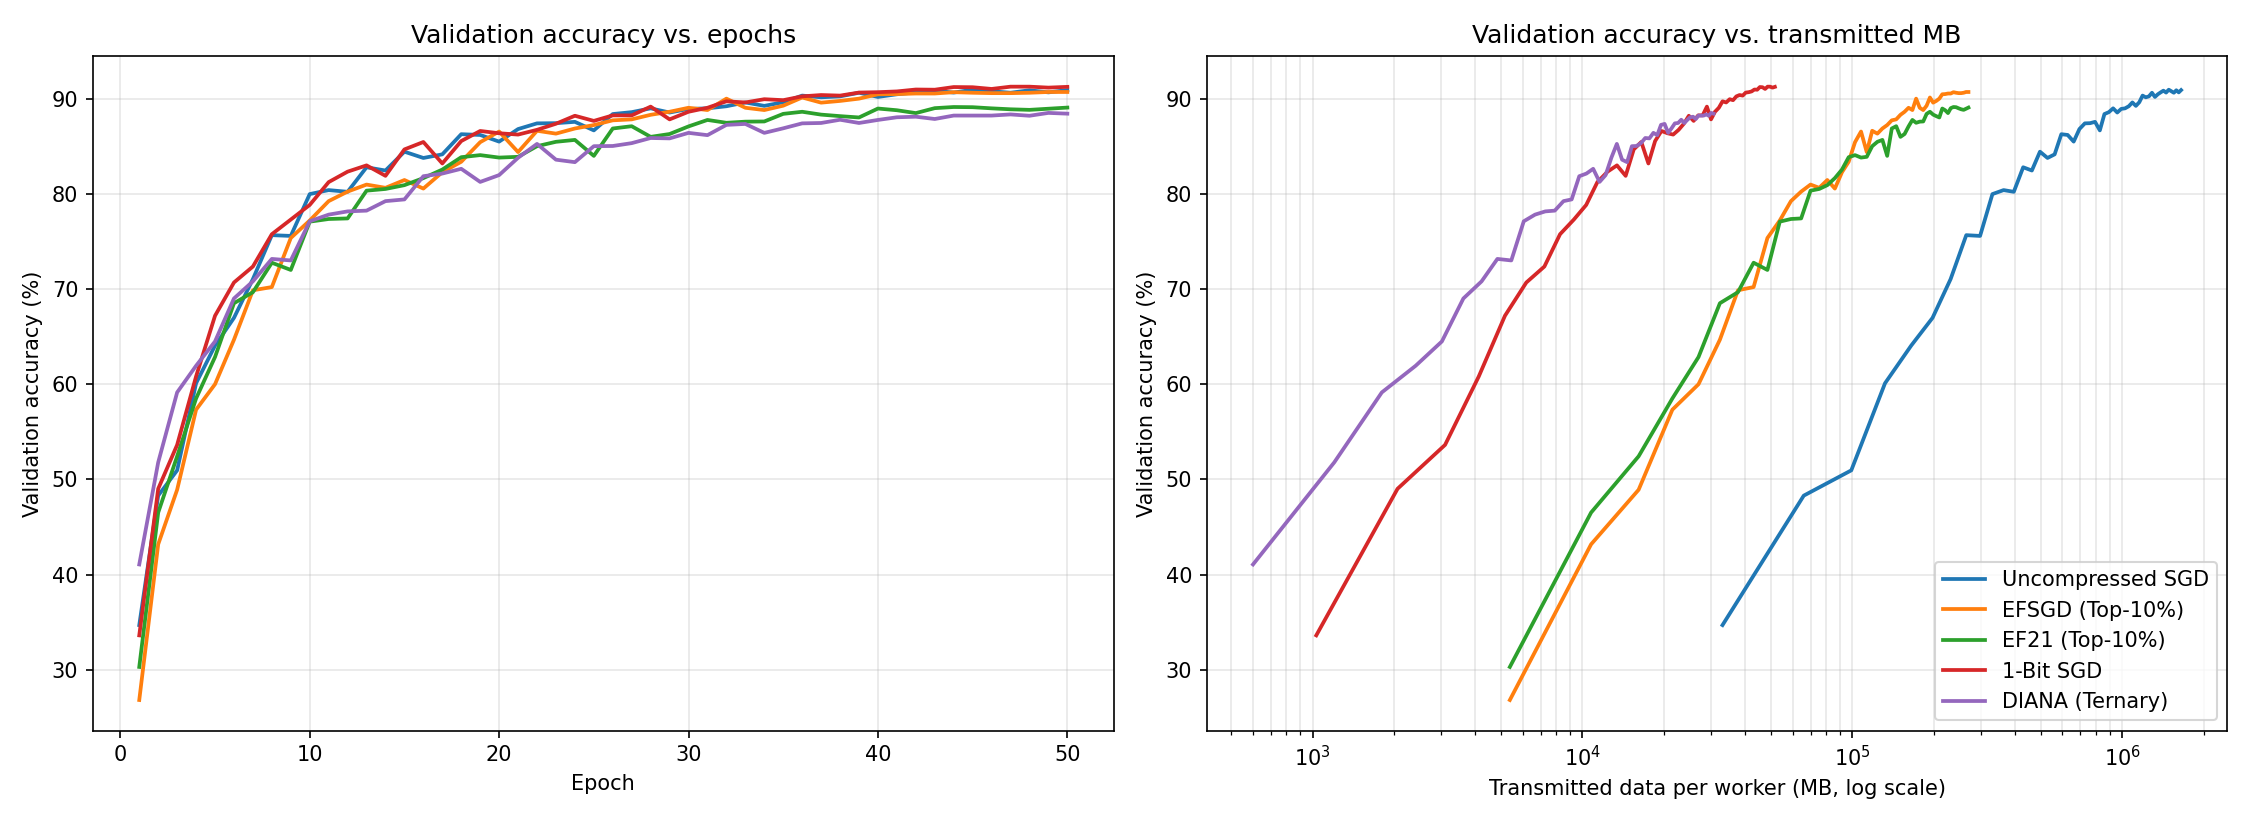

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for label, df in histories.items():
    axes[0].plot(df["epoch"], df["val_acc"], linewidth=1.8, label=label)
    axes[1].plot(df["mb"], df["val_acc"], linewidth=1.8, label=label)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation accuracy (%)")
axes[0].set_title("Validation accuracy vs. epochs")
axes[0].grid(alpha=0.3)

axes[1].set_xscale("log")
axes[1].set_xlabel("Transmitted data per worker (MB, log scale)")
axes[1].set_ylabel("Validation accuracy (%)")
axes[1].set_title("Validation accuracy vs. transmitted MB")
axes[1].grid(alpha=0.3, which="both")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "val_acc_curves.png"), dpi=150)
plt.show()

In [10]:
baseline = histories["Uncompressed SGD"]
target_acc = 0.95 * baseline["val_acc"].max()
baseline_mb = baseline["mb"].iloc[-1]
total_steps = len(train_loader) * EPOCHS

rows = []
for label, df in histories.items():
    reached = df[df["val_acc"] >= target_acc]
    rows.append({
        "Algorithm": label,
        "Best Val Acc (%)": df["val_acc"].max(),
        "Final Val Acc (%)": df["val_acc"].iloc[-1],
        "Last-5 Mean Val Acc (%)": df["val_acc"].tail(5).mean(),
        "Final Val Loss": df["val_loss"].iloc[-1],
        "Final Train Loss": df["train_loss"].iloc[-1],
        "Total MB / Worker": df["mb"].iloc[-1],
        "Compression vs SGD (x)": baseline_mb / df["mb"].iloc[-1],
        "Avg Bits / Param / Step": df["mb"].iloc[-1] * 8e6 / (PARAM_COUNT * total_steps),
        f"MB to {target_acc:.1f}% Val Acc": reached["mb"].iloc[0] if len(reached) else np.nan,
        f"Epochs to {target_acc:.1f}% Val Acc": reached["epoch"].iloc[0] if len(reached) else np.nan,
        "Train Time (min)": df["seconds"].sum() / 60,
    })

summary = pd.DataFrame(rows).set_index("Algorithm")
summary.to_csv(os.path.join(RESULTS_DIR, "summary.csv"))
summary.round(3)

,Best Val Acc (%),Final Val Acc (%),Last-5 Mean Val Acc (%),Final Val Loss,Final Train Loss,Total MB / Worker,Compression vs SGD (x),Avg Bits / Param / Step,MB to 86.5% Val Acc,Epochs to 86.5% Val Acc,Train Time (min)
Algorithm,,,,,,,,,,,
Uncompressed SGD,91.00,90.96,90.828,0.384,0.032,1651167.6,1.000,32.000,693490.4,21,142.293
EFSGD (Top-10%),90.76,90.76,90.696,0.372,0.040,269126.7,6.135,5.216,107650.7,20,155.625
EF21 (Top-10%),89.18,89.12,88.996,0.388,0.103,269126.7,6.135,5.216,139945.9,26,153.085
1-Bit SGD,91.32,91.30,91.248,0.358,0.034,51621.7,31.986,1.000,19616.3,19,158.618
DIANA (Ternary),88.56,88.48,88.396,0.427,0.118,30586.1,53.984,0.593,18313.9,30,149.097
